In [1]:
# Import packages
# For data manipulation
import numpy as np
import pandas as pd

# For data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# For displaying all of the columns in dataframes
pd.set_option("display.max_columns", None)

# For data modeling
from xgboost import XGBClassifier, XGBRegressor, plot_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# For metrics and helpful functions
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.tree import plot_tree

# For saving models
import pickle

In [2]:
# RUN THIS CELL TO IMPORT YOUR DATA.
# Load dataset into a dataframe
df0 = pd.read_csv("HR_comma_sep.csv")

# Display first few rows of the dataframe
df0.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
# Gather basic information about the data
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [4]:
# Gather descriptive statistics about the data
df0.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [5]:
# Display all column names
df0.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='object')

In [6]:
# Rename columns as needed
# Standardize to snake_case, correct misspellings, and make names more concise
df0 = df0.rename(columns={"Work_accident": "work_accident",
                          "average_montly_hours": "average_monthly_hours",
                          "time_spend_company": "tenure",
                          "Department": "department"})

# Display all column names after the update
df0.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_monthly_hours', 'tenure', 'work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='object')

In [7]:
# Check for missing values
df0.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_monthly_hours    0
tenure                   0
work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

In [8]:
# Check for duplicates
df0.duplicated().sum()

np.int64(3008)

In [9]:
# Inspect some rows containing duplicates as needed
df0[df0.duplicated()].head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
396,0.46,0.57,2,139,3,0,1,0,sales,low
866,0.41,0.46,2,128,3,0,1,0,accounting,low
1317,0.37,0.51,2,127,3,0,1,0,sales,medium
1368,0.41,0.52,2,132,3,0,1,0,RandD,low
1461,0.42,0.53,2,142,3,0,1,0,sales,low


In [10]:
# Drop duplicates and save resulting dataframe in a new variable as needed
df1 = df0.drop_duplicates(keep="first")

# Display first few rows of new dataframe as needed
df1.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


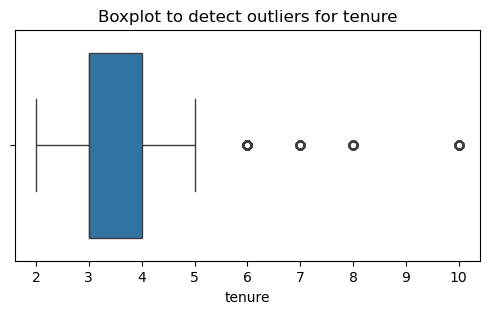

In [11]:
# Create a boxplot to visualize distribution of `tenure` and detect any outliers
plt.figure(figsize=(6, 3))
plt.title("Boxplot to detect outliers for tenure", fontsize=12)
sns.boxplot(x=df1["tenure"])
plt.show()

In [12]:
# Determine the number of rows containing outliers
q25 = df1["tenure"].quantile(0.25)
q75 = df1["tenure"].quantile(0.75)
iqr = q75 - q25
lower_limit = q25 - 1.5 * iqr
upper_limit = q75 + 1.5 * iqr

outliers = df1[(df1["tenure"] < lower_limit) | (df1["tenure"] > upper_limit)]
print("Lower limit:", lower_limit, "| Upper limit:", upper_limit)
print("Number of rows in the data containing outliers in `tenure`:", len(outliers))

Lower limit: 1.5 | Upper limit: 5.5
Number of rows in the data containing outliers in `tenure`: 824


In [13]:
# Get numbers of people who left vs. stayed
df1["left"].value_counts()

left
0    10000
1     1991
Name: count, dtype: int64

In [14]:
# Get percentages of people who left vs. stayed
df1["left"].value_counts(normalize=True)

left
0    0.833959
1    0.166041
Name: proportion, dtype: float64

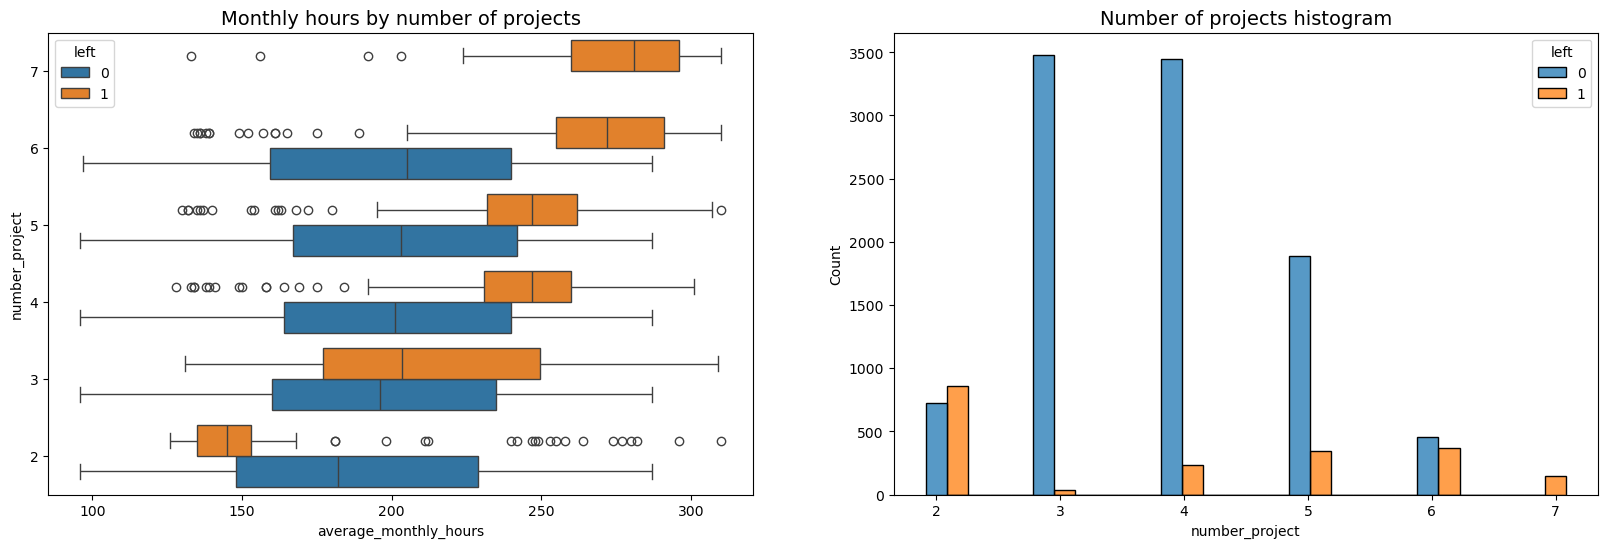

In [15]:
# 1. Hours worked by number of projects, split by left/stayed
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
sns.boxplot(data=df1, x="average_monthly_hours", y="number_project",
            hue="left", orient="h", ax=ax[0])
ax[0].invert_yaxis()
ax[0].set_title("Monthly hours by number of projects", fontsize=14)
sns.histplot(data=df1, x="number_project", hue="left", multiple="dodge",
             shrink=2, ax=ax[1])
ax[1].set_title("Number of projects histogram", fontsize=14)
plt.show()

In [16]:
# 2. Count of people who left vs. stayed for each number of projects
df1.groupby(["number_project", "left"]).size().unstack(fill_value=0)

left,0,1
number_project,,
2,725,857
3,3482,38
4,3448,237
5,1890,343
6,455,371
7,0,145


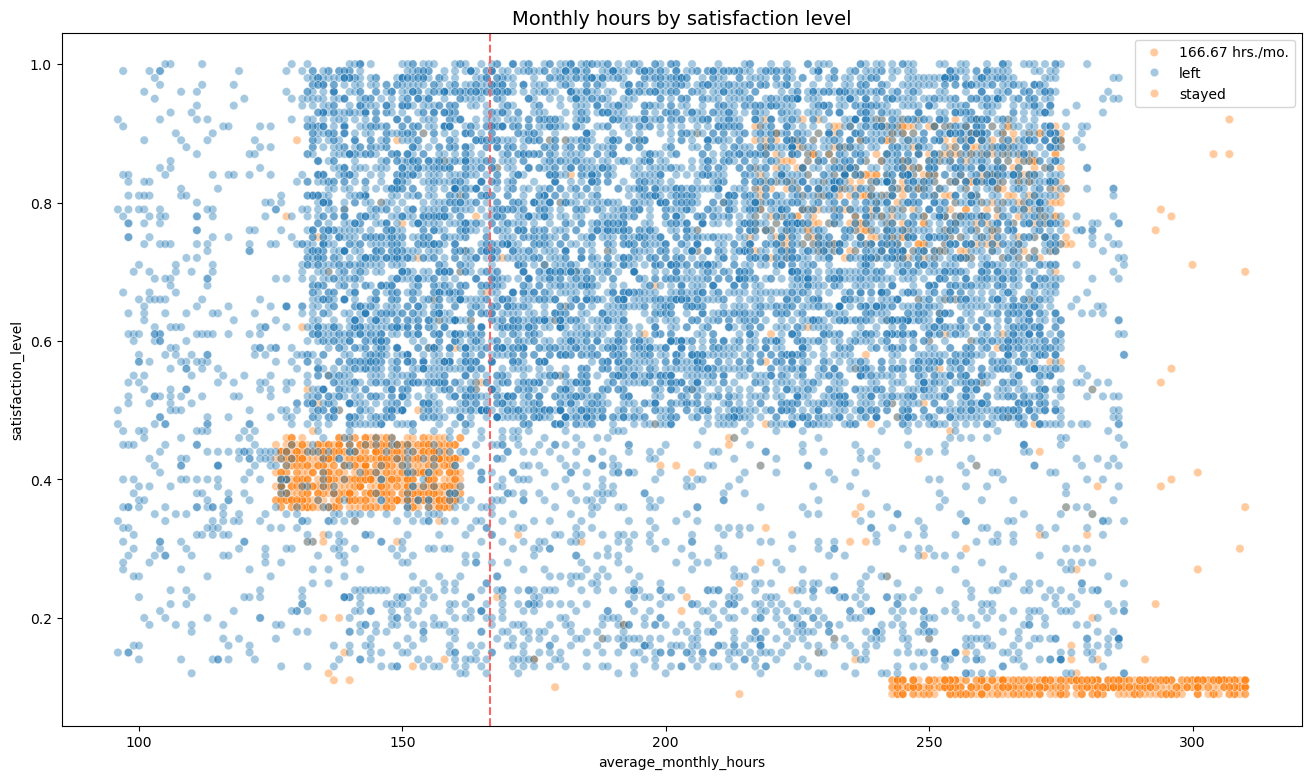

In [17]:
# 3. Monthly hours vs. satisfaction level
plt.figure(figsize=(16, 9))
sns.scatterplot(data=df1, x="average_monthly_hours", y="satisfaction_level",
                hue="left", alpha=0.4)
plt.axvline(x=166.67, color="#ff6361", label="166.67 hrs./mo.", ls="--")
plt.legend(labels=["166.67 hrs./mo.", "left", "stayed"])
plt.title("Monthly hours by satisfaction level", fontsize=14)
plt.show()

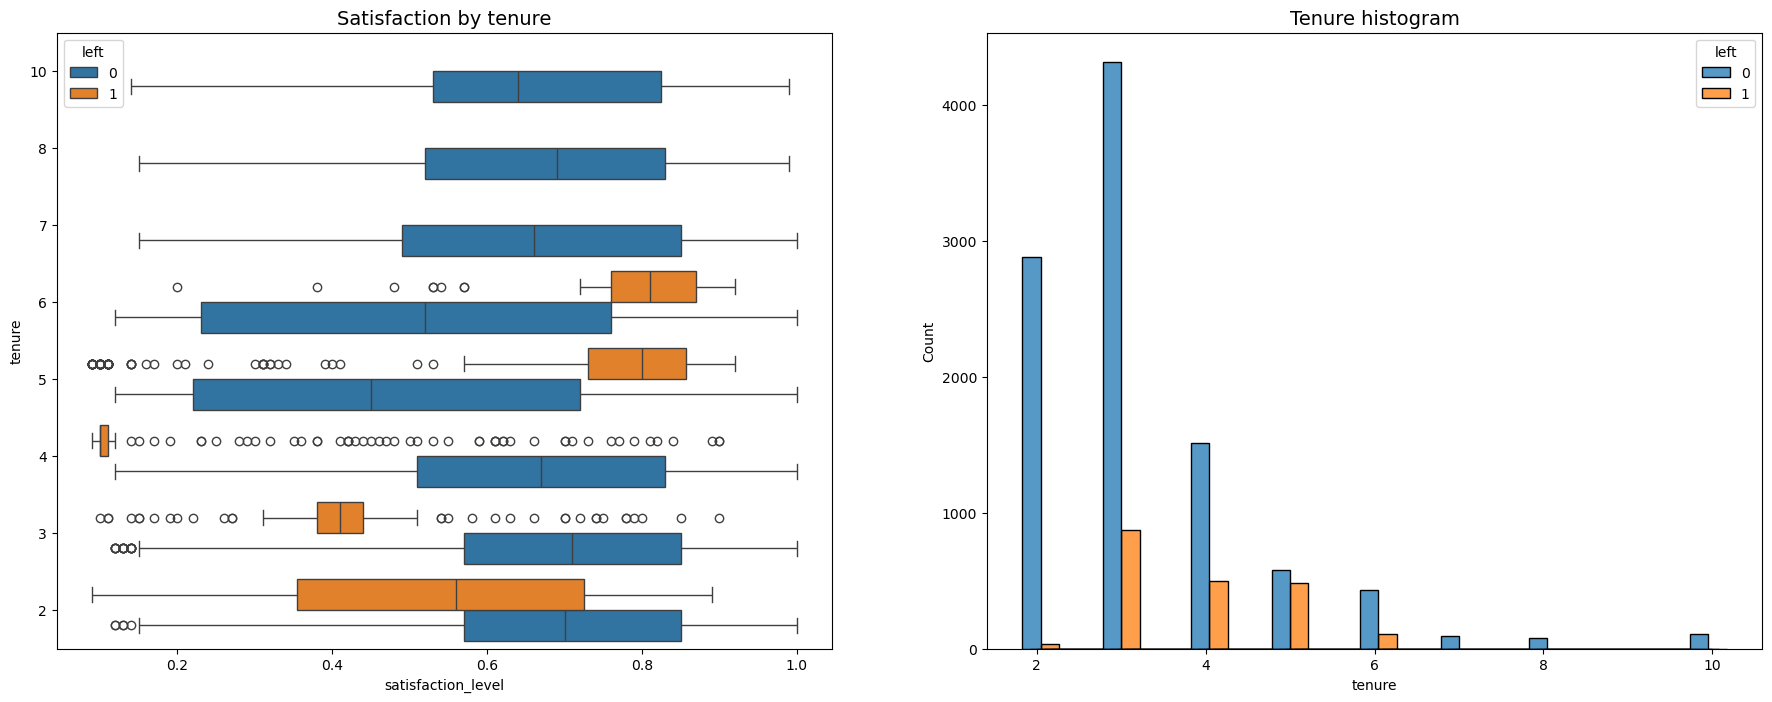

In [18]:
# 4. Satisfaction level by tenure
fig, ax = plt.subplots(1, 2, figsize=(22, 8))
sns.boxplot(data=df1, x="satisfaction_level", y="tenure",
            hue="left", orient="h", ax=ax[0])
ax[0].invert_yaxis()
ax[0].set_title("Satisfaction by tenure", fontsize=14)
sns.histplot(data=df1, x="tenure", hue="left", multiple="dodge",
             shrink=5, ax=ax[1])
ax[1].set_title("Tenure histogram", fontsize=14)
plt.show()

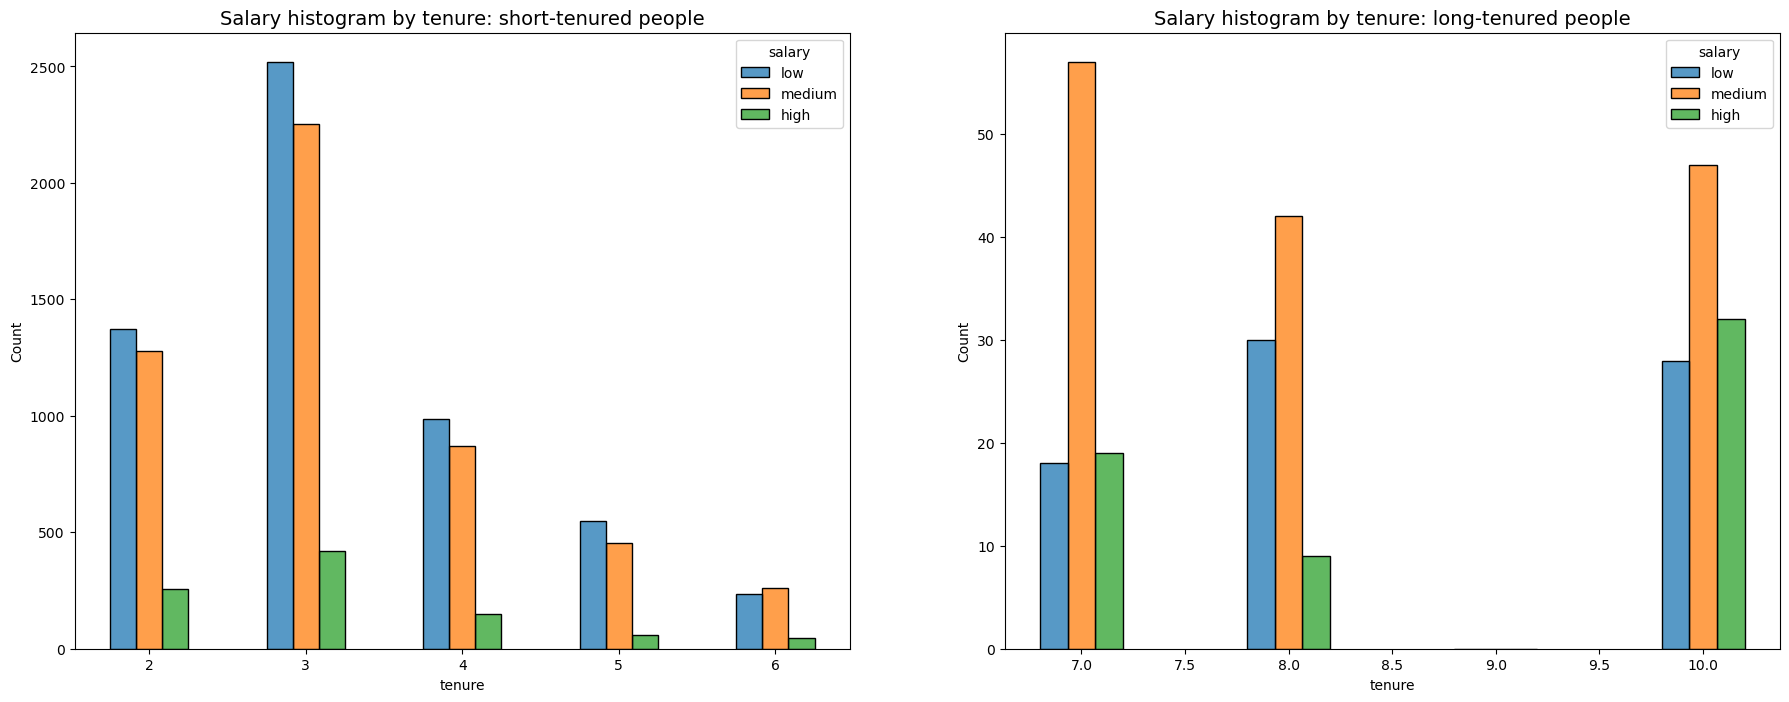

In [19]:
# 5. Salary levels for short- vs. long-tenured employees
fig, ax = plt.subplots(1, 2, figsize=(22, 8))
tenure_short = df1[df1["tenure"] < 7]
tenure_long = df1[df1["tenure"] > 6]
sns.histplot(data=tenure_short, x="tenure", hue="salary", discrete=1,
             hue_order=["low", "medium", "high"], multiple="dodge", shrink=0.5, ax=ax[0])
ax[0].set_title("Salary histogram by tenure: short-tenured people", fontsize=14)
sns.histplot(data=tenure_long, x="tenure", hue="salary", discrete=1,
             hue_order=["low", "medium", "high"], multiple="dodge", shrink=0.4, ax=ax[1])
ax[1].set_title("Salary histogram by tenure: long-tenured people", fontsize=14)
plt.show()

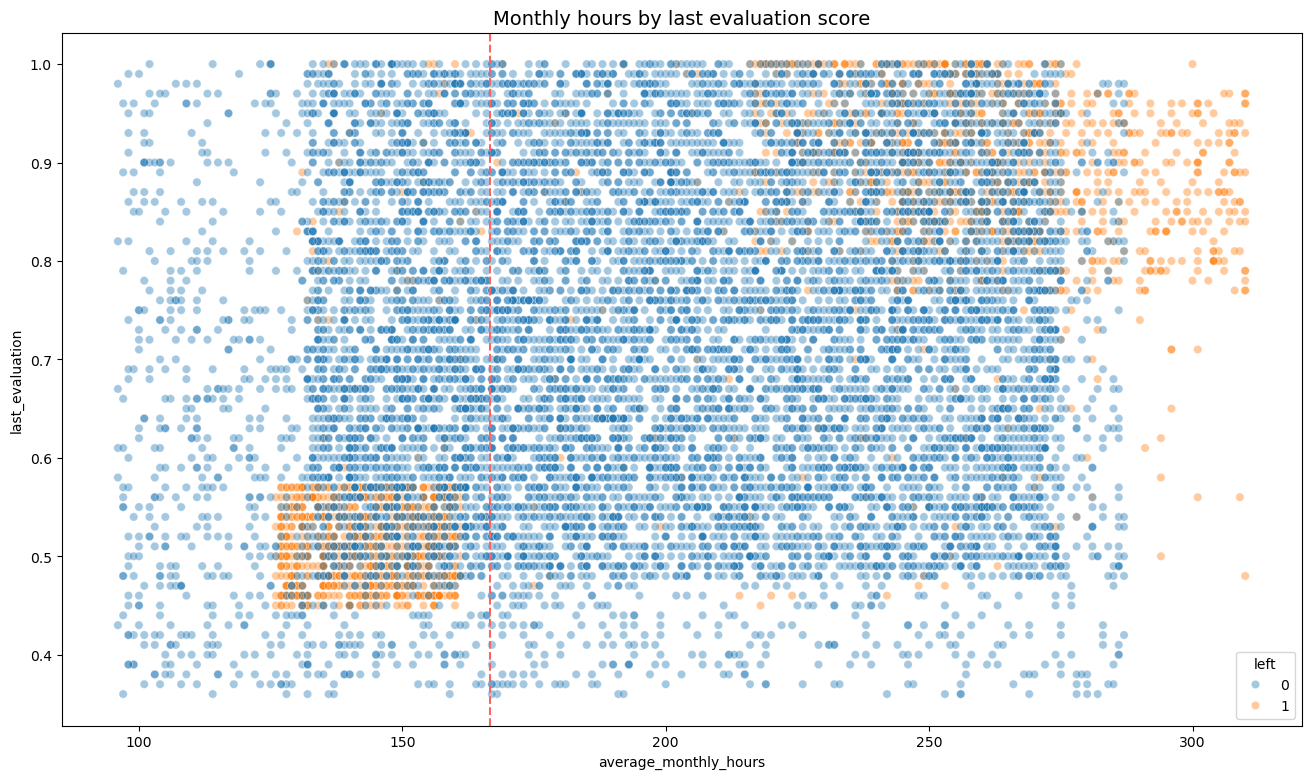

In [20]:
# 6. Monthly hours vs. last evaluation score
plt.figure(figsize=(16, 9))
sns.scatterplot(data=df1, x="average_monthly_hours", y="last_evaluation",
                hue="left", alpha=0.4)
plt.axvline(x=166.67, color="#ff6361", ls="--")
plt.title("Monthly hours by last evaluation score", fontsize=14)
plt.show()

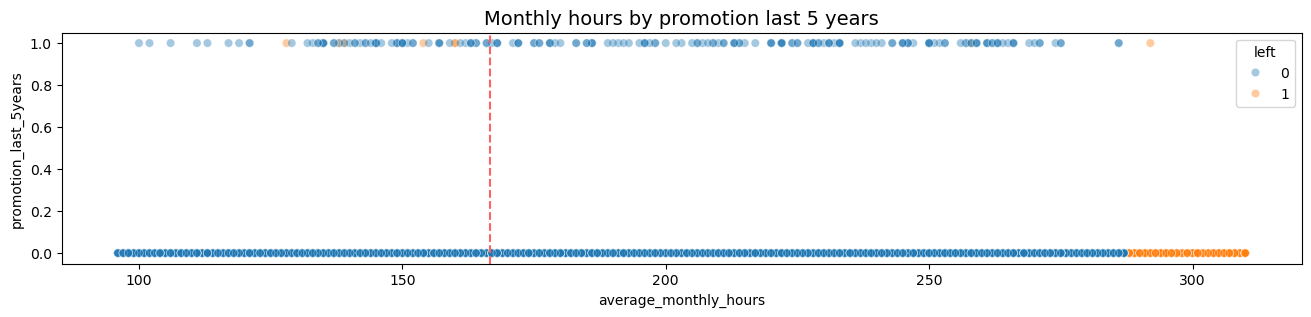

In [21]:
# 7. Monthly hours vs. promotion in the last 5 years
plt.figure(figsize=(16, 3))
sns.scatterplot(data=df1, x="average_monthly_hours", y="promotion_last_5years",
                hue="left", alpha=0.4)
plt.axvline(x=166.67, color="#ff6361", ls="--")
plt.title("Monthly hours by promotion last 5 years", fontsize=14)
plt.show()

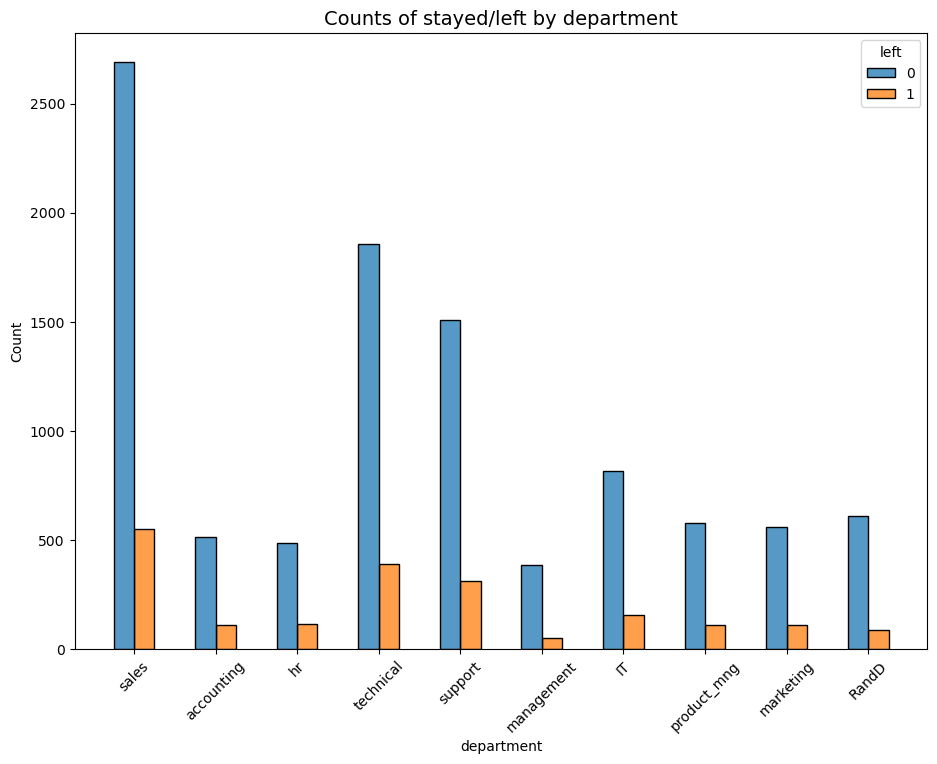

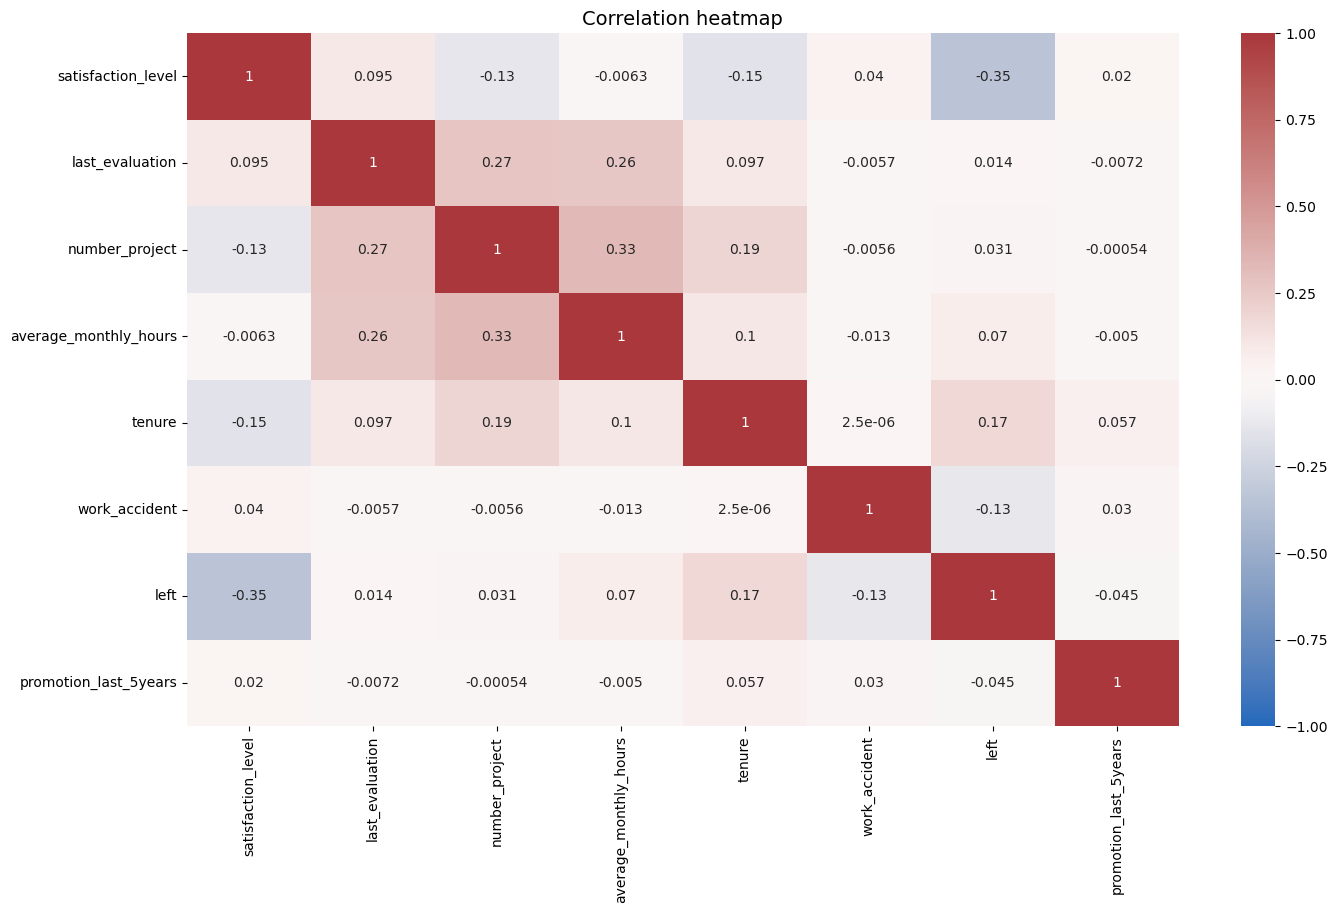

In [22]:
# 8a. Departments by left/stayed
plt.figure(figsize=(11, 8))
sns.histplot(data=df1, x="department", hue="left", discrete=1,
             hue_order=[0, 1], multiple="dodge", shrink=0.5)
plt.xticks(rotation=45)
plt.title("Counts of stayed/left by department", fontsize=14)
plt.show()

# 8b. Correlation heatmap
plt.figure(figsize=(16, 9))
heatmap = sns.heatmap(df1.select_dtypes(include="number").corr(),
                      vmin=-1, vmax=1, annot=True, cmap=sns.color_palette("vlag", as_cmap=True))
heatmap.set_title("Correlation heatmap", fontsize=14)
plt.show()

C:\Users\ajunc\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


                           precision    recall  f1-score   support

Predicted would not leave       0.86      0.93      0.90      2321
    Predicted would leave       0.44      0.26      0.33       471

                 accuracy                           0.82      2792
                macro avg       0.65      0.60      0.61      2792
             weighted avg       0.79      0.82      0.80      2792



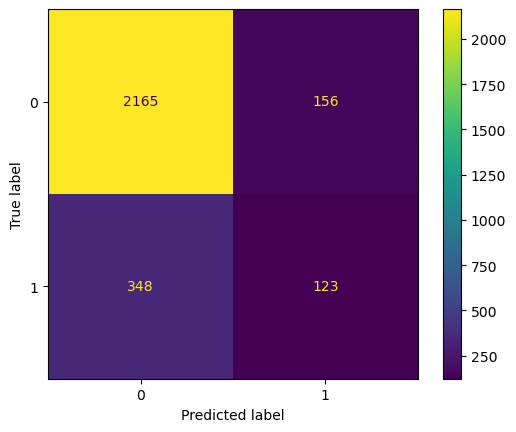

In [23]:
# Encode categorical variables
df_enc = df1.copy()
df_enc["salary"] = (df_enc["salary"].astype("category")
                    .cat.set_categories(["low", "medium", "high"]).cat.codes)
df_enc = pd.get_dummies(df_enc, drop_first=False)

# Logistic regression is sensitive to outliers, so remove `tenure` outliers
df_logreg = df_enc[(df_enc["tenure"] >= lower_limit) & (df_enc["tenure"] <= upper_limit)]

# Isolate target and features
y = df_logreg["left"]
X = df_logreg.drop("left", axis=1)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                    stratify=y, random_state=42)

# Fit the model
log_clf = LogisticRegression(random_state=42, max_iter=500).fit(X_train, y_train)

# Evaluate
y_pred = log_clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Predicted would not leave", "Predicted would leave"]))

cm = confusion_matrix(y_test, y_pred, labels=log_clf.classes_)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=log_clf.classes_).plot(values_format="")
plt.show()